# 05 · Carbon: when vs where, average vs marginal, clean hours vs rush hours

**Question.** For flexible AI work in Utah, how much CO₂ can *waiting* save, how much can *moving* to another region save, how much of the waiting gain survives if we count the emissions on the margin instead of on average, and are the grid's cleanest hours the same as its rush hours?

**Short answer.**
- **Waiting in PACE helps on average:** a 1-hour job that may start up to 24 h later, with perfect foresight, is charged 33 % less CO₂ on PACE's average intensity, because midday solar displaces gas while coal runs flat.
- **On the margin it helps far less.** PACE's estimated marginal intensity barely follows the solar trough (about 500–660 g/kWh in every block of the day). Scored on that proxy, the same schedule saves about nothing, and even a schedule built on the proxy saves at most about 10 %. Most of the 33 % is an accounting gain, not avoided emissions, so we report both and never call the average saving "avoided".
- **Where beats when.** Moving a PACE job to BPAT (hydro), CISO or NEVP cuts 94 %, 65 % and 42 % on production-based intensity, and 82 %, 67 % and 44 % on EIA's consumption basis. BPAT is cleaner than PACE in every hour, so moves need capacity limits or the answer is always "go to BPAT".
- **Clean hours ≠ rush hours in Utah.** PACE's demand and carbon intensity are slightly *anti*-correlated (r = −0.18): its rush hour is a sunny late afternoon, its dirtiest hours are coal nights. In NYIS, ISNE, PJM and DUK the rush hour *is* 20–36 % dirtier.

**How to read this notebook.** Carbon intensity (CI) is *modeled*: EIA-930 fuel mix × EIA's emission factors ("ours"), and EIA's own hourly CO₂ estimate from its per-BA workbooks (production and consumption basis). The marginal figure is an *exploratory association proxy* (a regression of hourly ΔCO₂ on Δnet load), not a causal estimate. Savings are perfect-foresight upper bounds on the validation year (2024-11 to 2025-10), not router results. Code: `lab/scripts/recon_grid.py` and `gridpilot.carbon`; profile: [`docs/data-profile/grid.md` §8](../docs/data-profile/grid.md#8-carbon-intensity-room-for-when-and-where).

**Seal.** Everything uses hours before 2025-11-01Z (`drop_sealed`, also applied to EIA's workbook series inside the recon's cross-check).

## 0. Inputs

In [1]:
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from gridpilot import notebook as nb
from gridpilot.carbon import wait_cut
from gridpilot.splits import TEST_START, drop_sealed

nb.setup()
SCRATCH = Path(tempfile.mkdtemp(prefix="nb05_"))
rg = nb.import_recon("recon_grid", SCRATCH)


def table(name: str) -> pl.DataFrame:
    return pl.read_csv(SCRATCH / f"{name}.csv")


CORE = ["PACE", "CISO", "BPAT", "AZPS", "NEVP", "PSCO", "ERCO", "SWPP", "MISO", "PJM"]
balance_path = rg.INTERIM_EIA_DIR / "balance.parquet"
print(nb.file_inventory([balance_path]).row(0, named=True))
pre = rg.add_derived(drop_sealed(pl.read_parquet(balance_path)))
assert pre["ts_utc"].max() < TEST_START
val = rg.val_year(pre)

{'file': '$GRIDPILOT_DATA_DIR/interim/eia930/balance.parquet', 'bytes': 126914246, 'sha256': 'f63d0c2703c6e42a1bbdabc9ff746ab0405cbc72b1c5a9dad8c6251ef29d0e86'}


## 1. Average carbon intensity by BA

Bars are each BA's validation-year average intensity of generation (production basis, ours); whiskers span the 10th–90th percentile of its hours. PACE is orange.

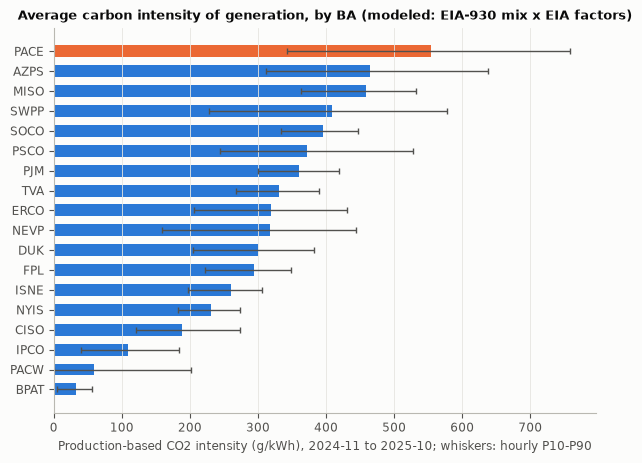

In [2]:
rg.carbon(pre, CORE)
nb.show(SCRATCH / "ci_by_ba.png")

**What the figure shows.** PACE is the dirtiest grid in the set (about 554 g/kWh, from 45 % coal), and also one of the widest: its 10th–90th percentile hours run from about 340 to 760 g/kWh. BPAT (hydro) sits near 33 g/kWh. The next table checks our fuel-mix intensity against EIA's own hourly estimate, on both bases.

In [3]:
rg.eia_co2_crosscheck(pre)
x = table("eia_co2_crosscheck")
x.select("ba", "hours", pl.col("ours_g_kwh").round(0), pl.col("eia_tons_over_posgen_g_kwh").round(0).alias("eia_generated_g_kwh"),
         pl.col("eia_consumed_intensity_g_kwh").round(0).alias("eia_consumed_g_kwh"),
         (pl.col("eia_consumed_intensity_g_kwh") / pl.col("eia_tons_over_posgen_g_kwh")).round(2).alias("consumed_over_generated"),
         pl.col("corr_hourly").round(2).alias("hourly_corr_ours_vs_eia")).sort("ours_g_kwh")

ba,hours,ours_g_kwh,eia_generated_g_kwh,eia_consumed_g_kwh,consumed_over_generated,hourly_corr_ours_vs_eia
"""BPAT""",8760,33.0,34.0,102.0,2.99,1.0
"""PACW""",8760,59.0,59.0,128.0,2.17,1.0
"""IPCO""",8760,109.0,103.0,249.0,2.41,0.99
"""CISO""",8688,189.0,166.0,186.0,1.12,0.97
"""NYIS""",8746,231.0,245.0,257.0,1.05,1.0
"""ISNE""",8758,260.0,236.0,238.0,1.01,1.0
"""FPL""",8757,294.0,249.0,264.0,1.06,1.0
"""DUK""",8760,300.0,274.0,274.0,1.0,0.97
"""NEVP""",8709,317.0,301.0,314.0,1.04,1.0
"""ERCO""",8760,318.0,315.0,315.0,1.0,1.0


**What the table shows.** Our intensity tracks EIA's hour by hour (correlation of about 0.97 or more for every BA except AZPS, at 0.76, because EIA divides by positive generation while we net out battery charging). The consumption basis, which follows imported power through EIA's flow model, matters most for hydro BAs that import: BPAT's consumed electricity is about 3× dirtier than what it generates (102 vs 34 g/kWh), IPCO's about 2.4×. That is why EIA's hourly CO₂ is the primary signal, with both bases reported side by side, and our fuel-mix intensity is the transparent fallback and the input to the marginal proxy.

The next figure shows each BA's intensity by local hour and season.

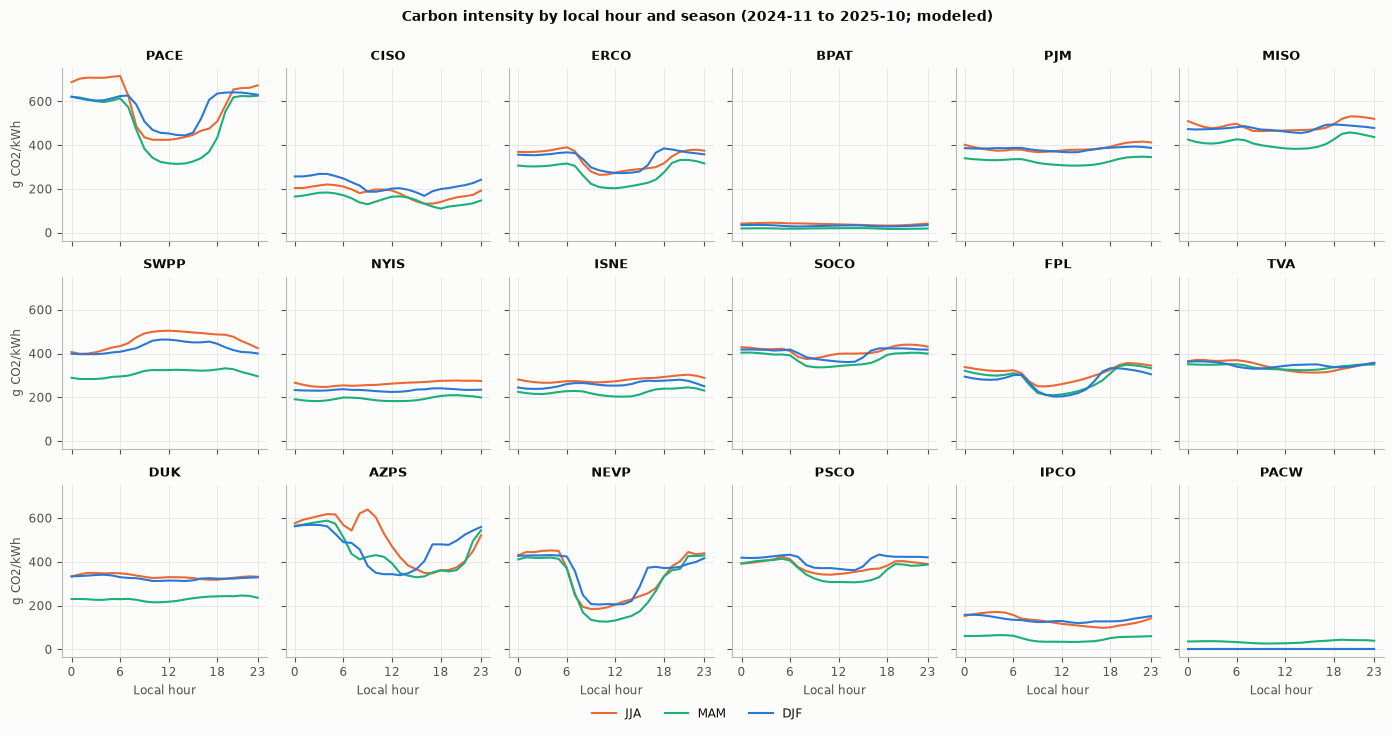

In [4]:
nb.show(SCRATCH / "ci_diurnal.png")

**What the figure shows.** Solar-heavy BAs (PACE, CISO, NEVP, AZPS, ERCO) have a deep midday trough, deepest in spring (green) and summer (orange); nuclear- and gas-flat grids (PJM, MISO, TVA, NYIS) barely move through the day. The trough is the room a time-shifting router has.

## 2. PACE: average vs marginal

**Average.** With perfect foresight, a 1-hour job that may start any time in the next W hours picks the cleanest of them. `gridpilot.carbon.wait_cut` computes the resulting cut for every W, on PACE's hourly average intensity; at W = 6 and 24 it reproduces the profile's 15 % and 33 %.

**Marginal (exploratory).** The marginal intensity asks what *extra* CO₂ one more MWh causes. The proxy is the slope of hourly ΔCO₂ on Δnet load, fitted on the validation year, overall and per 6-hour local block (Siler-Evans et al. 2012 style; R² 0.47 for PACE). We then ask: if a router schedules on the *average* signal, how much does it save when the same moves are scored on the *marginal* proxy?

In [5]:
rg.marginal_ci(pre)
mef = table("marginal_ci_validation_year")
mef.filter(pl.col("ba").is_in(CORE + ["NYIS"])).select(
    "ba", pl.col("avg_ci").round(0).alias("average_g_kwh"), pl.col("mef_netload_g_kwh").round(0).alias("marginal_g_kwh"),
    pl.col("r2_netload").round(2).alias("R2"), *[pl.col(f"mef_{a:02d}-{a + 6:02d}h").round(0) for a in (0, 6, 12, 18)])

ba,average_g_kwh,marginal_g_kwh,R2,mef_00-06h,mef_06-12h,mef_12-18h,mef_18-24h
"""PACE""",554.0,618.0,0.47,497.0,658.0,498.0,550.0
"""CISO""",189.0,12.0,0.01,143.0,5.0,61.0,34.0
"""ERCO""",318.0,401.0,0.89,483.0,397.0,489.0,346.0
"""BPAT""",33.0,6.0,0.02,12.0,6.0,1.0,7.0
"""PJM""",360.0,437.0,0.72,569.0,421.0,449.0,404.0
"""MISO""",458.0,574.0,0.87,749.0,582.0,551.0,496.0
"""SWPP""",409.0,572.0,0.88,611.0,579.0,584.0,613.0
"""NYIS""",231.0,328.0,0.73,410.0,350.0,342.0,310.0
"""AZPS""",465.0,119.0,0.33,76.0,118.0,131.0,87.0
"""NEVP""",317.0,235.0,0.13,129.0,264.0,165.0,137.0


In [6]:
p = val.filter((pl.col("ba") == "PACE") & pl.col("ci_g_kwh").is_not_null()).sort("ts_utc")
ci = p["ci_g_kwh"].to_numpy().astype(float)
m = mef.filter(pl.col("ba") == "PACE").row(0, named=True)
block_mef = np.array([m[f"mef_{a:02d}-{a + 6:02d}h"] for a in (0, 6, 12, 18)])
mef_series = block_mef[p["hour_local"].to_numpy() // 6]
waits = list(range(0, 49))
curve = pl.DataFrame({
    "max_wait_h": waits,
    "average_CI_cut_%": [100 * wait_cut(ci, w) for w in waits],
    "same_moves_on_marginal_proxy_%": [100 * wait_cut(ci, w, evaluate_on=mef_series) for w in waits],
    "marginal_aware_moves_%": [100 * wait_cut(mef_series, w) for w in waits],
})
print(f"{len(ci):,} PACE hours; hours with no CI value dropped: {val.filter(pl.col('ba') == 'PACE').height - len(ci)}")
hp = p.group_by("hour_local").agg(pl.col("ci_g_kwh").mean().alias("ci")).sort("ci")
print(f"PACE average CI by local hour: lowest {hp['ci'][0]:.0f} g/kWh at {hp['hour_local'][0]}:00, "
      f"highest {hp['ci'][-1]:.0f} g/kWh at {hp['hour_local'][-1]}:00")
curve.filter(pl.col("max_wait_h").is_in([1, 3, 6, 12, 24, 48])).with_columns(pl.exclude("max_wait_h").round(1))

8,760 PACE hours; hours with no CI value dropped: 0
PACE average CI by local hour: lowest 406 g/kWh at 13:00, highest 658 g/kWh at 6:00


max_wait_h,average_CI_cut_%,same_moves_on_marginal_proxy_%,marginal_aware_moves_%
1,3.0,0.4,1.6
3,8.3,0.6,4.9
6,14.9,0.1,9.7
12,25.5,-1.1,9.7
24,33.3,-1.0,9.8
48,39.0,-0.8,9.8


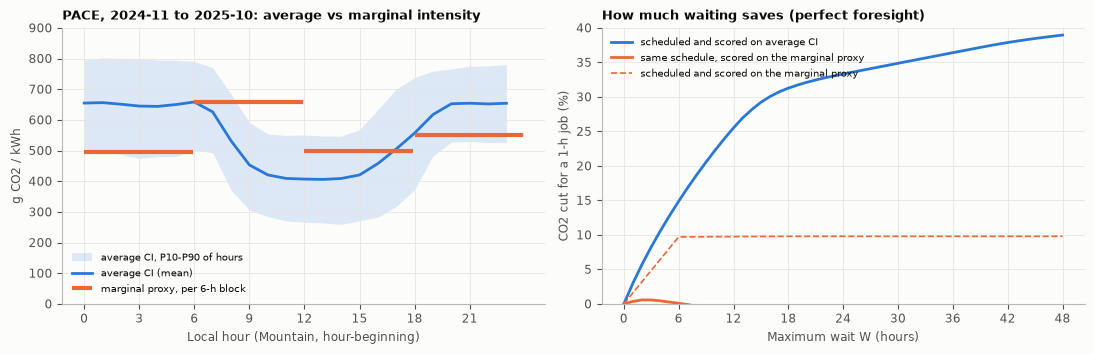

In [7]:
hourly = (p.group_by("hour_local").agg(pl.col("ci_g_kwh").mean().alias("avg"),
                                       pl.col("ci_g_kwh").quantile(0.1).alias("p10"),
                                       pl.col("ci_g_kwh").quantile(0.9).alias("p90")).sort("hour_local"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
h = hourly["hour_local"].to_numpy()
a1.fill_between(h, hourly["p10"], hourly["p90"], color="#2a78d6", alpha=0.15, lw=0, label="average CI, P10-P90 of hours")
a1.plot(h, hourly["avg"], color="#2a78d6", lw=2, label="average CI (mean)")
for k, v in enumerate(block_mef):
    a1.hlines(v, 6 * k, 6 * k + 5.9, color="#eb6834", lw=3, label="marginal proxy, per 6-h block" if k == 0 else None)
a1.set(xlabel="Local hour (Mountain, hour-beginning)", ylabel="g CO2 / kWh", xticks=range(0, 24, 3), ylim=(0, 900))
a1.set_title("PACE, 2024-11 to 2025-10: average vs marginal intensity", loc="left")
a1.legend(fontsize=7.5, loc="lower left")
a2.plot(curve["max_wait_h"], curve["average_CI_cut_%"], color="#2a78d6", lw=2, label="scheduled and scored on average CI")
a2.plot(curve["max_wait_h"], curve["same_moves_on_marginal_proxy_%"], color="#eb6834", lw=2,
        label="same schedule, scored on the marginal proxy")
a2.plot(curve["max_wait_h"], curve["marginal_aware_moves_%"], color="#eb6834", lw=1.2, ls="--",
        label="scheduled and scored on the marginal proxy")
a2.set(xlabel="Maximum wait W (hours)", ylabel="CO2 cut for a 1-h job (%)", xticks=range(0, 49, 6), ylim=(0, 40))
a2.set_title("How much waiting saves (perfect foresight)", loc="left")
a2.legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
plt.show()

**What the figure shows.** Left: PACE's average intensity (blue, with the spread of its hours) is highest in the early morning and lowest in the early afternoon (the numbers are printed above the figure), while the marginal proxy (orange bars) stays between roughly 500 and 660 g/kWh in every block, lowest overnight and in the afternoon, highest in the morning. Right: the blue curve is the average-accounting gain from waiting, rising to 33 % at 24 h. Scoring the same schedule on the marginal proxy (solid orange) leaves about nothing (around 0 %, slightly negative beyond 12 h), because the schedule mostly moves night work to midday and the proxy rates those two blocks the same. Even a router that schedules on the proxy itself (dashed orange) saves at most about 10 %, and that bound rests on four noisy block coefficients.

**Reading it honestly.** The marginal proxy is an association fitted on one year (R² 0.47) that ignores imports, curtailment and weather confounding; it is a sensitivity, not the truth. But it is enough to say that PACE's 33 % is mostly a statement about *which* plants are running at noon, not about emissions a data centre would avoid by waiting. Hence the "skeptic mode" in the dashboard (average → consumption → marginal) and the rule that an average-CI saving is never called avoided emissions.

## 3. Move vs wait

Each bar is the cut in CO₂ for a 1-hour PACE job, against running it in PACE right away (validation year, perfect foresight, hours where both BAs have a value). "Wait" options stay in PACE; "move" options run the job in the same hour in another BA; "move + wait" moves it and lets it start at the cleanest of the next 24 hours there. Hatched bars use EIA's consumption-based intensity (ratio of validation-year means) instead of production-based.

In [8]:
wide = (val.filter(pl.col("ba").is_in(["PACE", "BPAT", "CISO", "NEVP"]))
        .pivot(on="ba", index="ts_utc", values="ci_g_kwh").drop_nulls().sort("ts_utc"))
pace_ci = wide["PACE"].to_numpy().astype(float)
eia = {r["ba"]: r for r in x.iter_rows(named=True)}
rows = [{"option": "wait <= 6 h in PACE", "basis": "production", "cut_%": 100 * wait_cut(pace_ci, 6)},
        {"option": "wait <= 24 h in PACE", "basis": "production", "cut_%": 100 * wait_cut(pace_ci, 24)}]
for ba in ("NEVP", "CISO", "BPAT"):
    dest = wide[ba].to_numpy().astype(float)
    later = np.arange(len(dest)) + np.array([np.argmin(dest[t:t + 25]) for t in range(len(dest))])
    rows += [{"option": f"move to {ba}", "basis": "production", "cut_%": 100 * (1 - dest.sum() / pace_ci.sum())},
             {"option": f"move to {ba}", "basis": "consumption (EIA)",
              "cut_%": 100 * (1 - eia[ba]["eia_consumed_intensity_g_kwh"] / eia["PACE"]["eia_consumed_intensity_g_kwh"])},
             {"option": f"move to {ba} + wait <= 24 h", "basis": "production", "cut_%": 100 * (1 - dest[later].sum() / pace_ci.sum())}]
mw = pl.DataFrame(rows).with_columns(pl.col("cut_%").round(1))
print(f"{wide.height:,} hours with all four BAs")
mw

8,685 hours with all four BAs


option,basis,cut_%
"""wait <= 6 h in PACE""","""production""",15.0
"""wait <= 24 h in PACE""","""production""",33.3
"""move to NEVP""","""production""",41.7
"""move to NEVP""","""consumption (EIA)""",44.4
"""move to NEVP + wait <= 24 h""","""production""",70.6
"""move to CISO""","""production""",65.4
"""move to CISO""","""consumption (EIA)""",67.0
"""move to CISO + wait <= 24 h""","""production""",75.9
"""move to BPAT""","""production""",93.9
"""move to BPAT""","""consumption (EIA)""",81.9


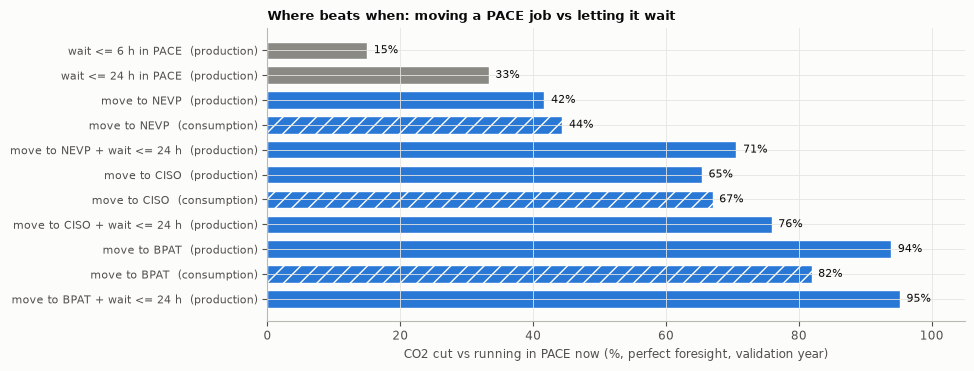

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = mw["option"].to_list()
colors = ["#8a8984" if o.startswith("wait") else "#2a78d6" for o in labels]
hatch = ["//" if b != "production" else "" for b in mw["basis"].to_list()]
y = np.arange(mw.height)[::-1]
bars = ax.barh(y, mw["cut_%"], color=colors, edgecolor="white", height=0.7)
for b, hh in zip(bars, hatch):
    b.set_hatch(hh)
ax.set_yticks(y, [f"{o}  ({'consumption' if b != 'production' else 'production'})" for o, b in zip(labels, mw["basis"].to_list())],
              fontsize=8)
for yy, v in zip(y, mw["cut_%"]):
    ax.text(v + 1, yy, f"{v:.0f}%", va="center", fontsize=8)
ax.set(xlim=(0, 105), xlabel="CO2 cut vs running in PACE now (%, perfect foresight, validation year)")
ax.set_title("Where beats when: moving a PACE job vs letting it wait", loc="left")
plt.show()

In [10]:
pv = rg.NUMBERS["cross_region"]["pace_vs"]
pl.DataFrame([{"destination": b, "mean_CI_difference_vs_PACE_g_kwh": round(v["mean_diff_g_kwh"]),
               "share_of_hours_cleaner_than_PACE_%": round(v["share_hours_other_cleaner_%"], 1)}
              for b, v in pv.items()]).sort("mean_CI_difference_vs_PACE_g_kwh", descending=True)

destination,mean_CI_difference_vs_PACE_g_kwh,share_of_hours_cleaner_than_PACE_%
"""BPAT""",523,100.0
"""CISO""",364,99.8
"""ERCO""",239,96.8
"""NEVP""",232,98.7
"""PJM""",203,89.4
"""PSCO""",181,89.0
"""SWPP""",154,76.1
"""MISO""",103,73.5
"""AZPS""",78,71.5


**What the figure and table show.** Waiting in PACE tops out at a third (on average accounting, §2). Moving the same hour of work to NEVP, CISO or BPAT cuts 42 %, 65 % and 94 %; the consumption basis narrows BPAT's lead (82 %) because BPAT imports dirtier power, but does not change the order. Moving and then waiting adds more where the destination has a solar trough (NEVP, CISO). BPAT is cleaner than PACE in every validation-year hour and CISO in 99.8 %: an unconstrained router would send everything to BPAT, which no real fleet could absorb. So move vs wait is in the core with destination capacity limits and migration rules, and the evaluation separates time-only, place-only and combined policies.

## 4. Clean hours ≠ rush hours

If the grid's rush hours were also its dirtiest, avoiding the rush and cutting carbon would be the same thing. The table compares, per BA and over the validation year, the correlation between hourly demand and intensity, and how much dirtier the year's 100 highest-demand hours are than the BA's average (median over 2019–2024).

In [11]:
ci_tab = table("ci_candidates_validation_year").select("ba", (pl.col("corr_demand_ci") / 100).round(2).alias("corr_demand_CI"))
rush = table("ci_rush_hour").rename({"ci_top100_vs_mean_%": "CI_in_top100_demand_h_vs_mean_%"})
prof = (val.filter(pl.col("demand_clean_mw").is_not_null() & pl.col("ci_g_kwh").is_not_null())
        .group_by("ba", "hour_local").agg(pl.col("demand_clean_mw").mean().alias("d"), pl.col("ci_g_kwh").mean().alias("c")))
hours = prof.with_columns(pl.col("ba").cast(pl.Utf8)).group_by("ba").agg(
    pl.col("hour_local").sort_by("d").last().alias("peak_demand_hour_local"),
                                pl.col("hour_local").sort_by("c").first().alias("cleanest_hour_local"),
                                pl.col("hour_local").sort_by("c").last().alias("dirtiest_hour_local"))
cr = (ci_tab.join(rush, on="ba").join(hours, on="ba")
      .filter(pl.col("ba").is_in(CORE + ["IPCO", "NYIS", "ISNE", "DUK"])).sort("ba"))
cr.with_columns(pl.col("CI_in_top100_demand_h_vs_mean_%").round(0)).sort("corr_demand_CI")

ba,corr_demand_CI,CI_in_top100_demand_h_vs_mean_%,peak_demand_hour_local,cleanest_hour_local,dirtiest_hour_local
"""PACE""",-0.18,3.0,17,13,6
"""NEVP""",-0.14,6.0,17,10,4
"""PSCO""",-0.12,6.0,17,13,5
"""BPAT""",-0.05,1.0,18,18,3
"""AZPS""",-0.03,-7.0,18,15,4
"""CISO""",-0.02,27.0,20,16,4
"""ERCO""",0.04,10.0,17,11,20
"""IPCO""",0.16,28.0,17,15,2
"""SWPP""",0.36,23.0,17,2,12
"""MISO""",0.42,11.0,17,14,20


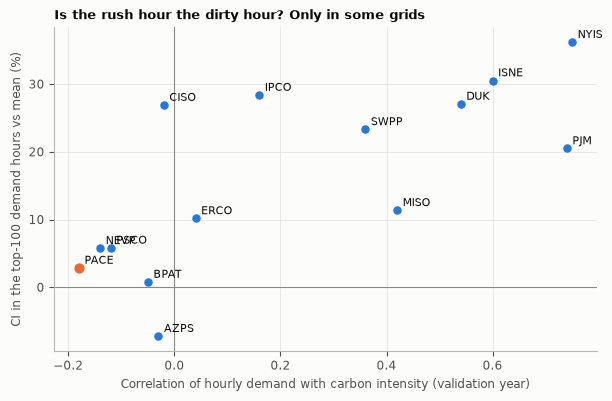

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for r in cr.iter_rows(named=True):
    hot = r["ba"] == "PACE"
    ax.scatter(r["corr_demand_CI"], r["CI_in_top100_demand_h_vs_mean_%"], s=40 if hot else 26,
               color="#eb6834" if hot else "#2a78d6", zorder=3)
    ax.annotate(r["ba"], (r["corr_demand_CI"], r["CI_in_top100_demand_h_vs_mean_%"]), textcoords="offset points",
                xytext=(4, 3), fontsize=8)
ax.axhline(0, color="#8a8984", lw=0.8)
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set(xlabel="Correlation of hourly demand with carbon intensity (validation year)",
       ylabel="CI in the top-100 demand hours vs mean (%)")
ax.set_title("Is the rush hour the dirty hour? Only in some grids", loc="left")
plt.show()

**What the table and figure show.** In the upper right are NYIS, ISNE, PJM and DUK: when demand rises, gas peakers run, and the 100 busiest hours are 20–36 % dirtier than average. Avoiding the rush there also cuts carbon. PACE sits near the origin on the left: its demand peaks at 17:00 on sunny summer days, when solar is still high, and its dirtiest hours are at night, when coal carries the load. The week below shows it directly.

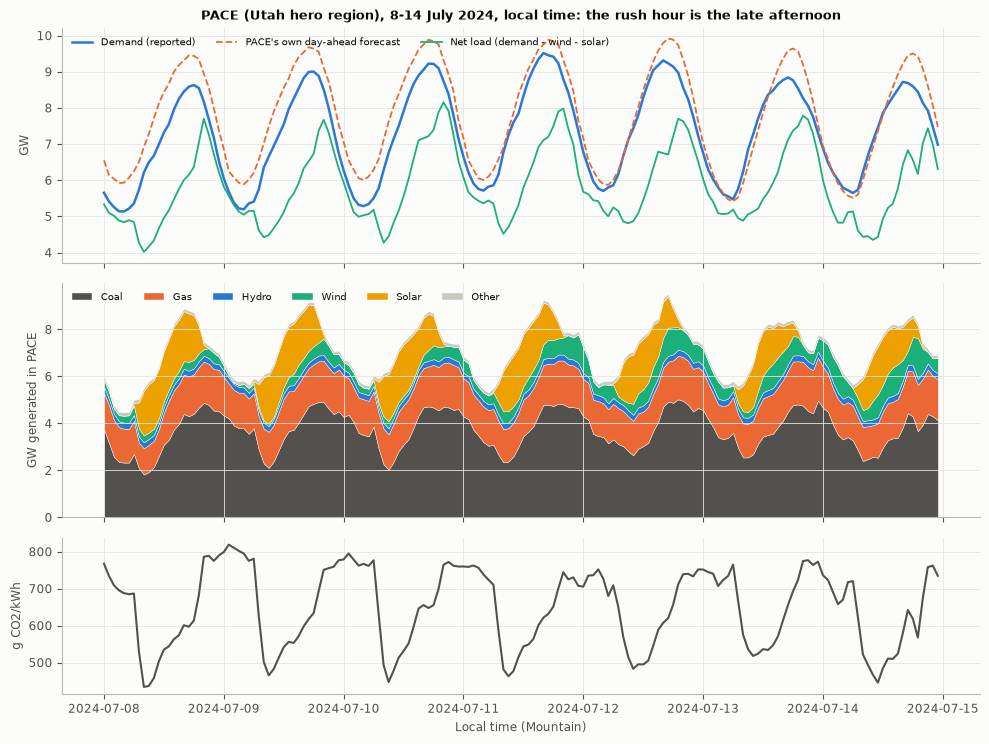

In [13]:
rg.pace_week(pre)
nb.show(SCRATCH / "pace_week_jul2024.png")
shutil.rmtree(SCRATCH)

**What the figure shows.** One July week in PACE (local time). Top: demand peaks each late afternoon, and PACE's own day-ahead forecast follows it; net load peaks later, after sunset. Middle: coal (dark grey) runs nearly flat day and night while solar (yellow) fills the middle of the day. Bottom: carbon intensity is lowest around midday and highest overnight, so the cleanest hours come several hours *before* the rush hour, and the dirtiest hours are in the middle of the night.

**Consequence.** An emissions-first router in Utah moves work from coal nights into solar middays; it does not mainly move work out of the 17:00–20:00 rush. Grid-stress hours avoided are reported as a secondary outcome, measured separately, never traded against emissions with arbitrary weights.

## Decisions this supports

From the [decision log](../docs/decisions.md):
- **D-027**: EIA's hourly CO₂ is the primary average-CI signal, production and consumption bases side by side; our fuel-mix CI is the fallback and the marginal-proxy input (§1).
- **D-028**: report average and marginal; never headline PACE's 33 % average-CI gain as avoided emissions (§2).
- **D-011**: wording is "attributed operational emissions"; the marginal regression is an exploratory proxy (§2).
- **D-029**: move vs wait is in the core, with destination capacity limits (§3).
- **D-013**: evaluate time-only, place-only and combined policies separately (§3).
- **D-030**: the second insight, "clean hours ≠ rush hours"; stress is a secondary outcome (§4).
- **D-018**: emissions first, with stress and cost reported separately (§2–§4).